# 01 · Inspect the raw hourly data

Goal: understand what Yahoo gives us *before* building features on it.
Questions:
1. Do all tickers share the same timestamps?
2. What does a trading day look like (bars per day, odd days)?
3. Is the first bar of the day really different (overnight gap)?
4. How liquid is ICHR?

Data comes from `uv run python -m semiconductor_affairs.ingest`.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from semiconductor_affairs.ingest import DATA_DIR, TARGET, TICKERS

bars = {t: pd.read_parquet(DATA_DIR / f"{t}.parquet") for t in TICKERS}
bars[TARGET].head(10)

,open,high,low,close,volume
timestamp,,,,,
2023-12-26 14:30:00+00:00,33.830002,34.233700,33.830002,34.000000,11053
2023-12-26 15:30:00+00:00,34.078098,34.080002,33.900002,34.029999,4861
2023-12-26 16:30:00+00:00,34.070000,34.380001,34.070000,34.380001,9676
2023-12-26 17:30:00+00:00,34.340000,34.450001,34.340000,34.424999,6525
2023-12-26 18:30:00+00:00,34.470001,34.610001,34.400002,34.610001,13709
2023-12-26 19:30:00+00:00,34.574299,34.764999,34.484001,34.619999,33938
2023-12-26 20:30:00+00:00,34.685001,34.794998,34.509998,34.599998,33299
2023-12-27 14:30:00+00:00,34.820000,34.869999,34.372002,34.750000,11138
2023-12-27 15:30:00+00:00,34.650002,34.709999,34.330101,34.540001,7641


## 1. Shared timestamps?
Count, per ticker, the bars that are missing compared with the union of all timestamps.
A missing bar means *no trades in that hour* (or a Yahoo gap). We have to decide how to fill it later.

In [2]:
all_ts = sorted(set().union(*(df.index for df in bars.values())))
all_ts = pd.DatetimeIndex(all_ts)
missing = {t: all_ts.difference(df.index) for t, df in bars.items()}
pd.Series({t: len(m) for t, m in missing.items()}, name="missing bars")

ICHR    0
LRCX    0
AMAT    0
KLAC    0
ASML    0
TSM     0
NVDA    0
UCTT    1
SOXX    0
QQQ     0
Name: missing bars, dtype: int64

In [3]:
{t: list(m) for t, m in missing.items() if len(m)}

{'UCTT': [Timestamp('2025-10-09 17:30:00+0000', tz='UTC')]}

## 2. What does a trading day look like?
Convert to New York time, since the US market hours are defined there.

In [4]:
ny = bars[TARGET].index.tz_convert("America/New_York")
per_day = pd.Series(ny.date).value_counts()
print("bars per day -> number of days")
print(per_day.value_counts().sort_index())
print("\nunusual days:")
print(per_day[per_day != 7].sort_index())

bars per day -> number of days
count
2      1
3      6
6      1
7    721
Name: count, dtype: int64

unusual days:
2024-07-03    3
2024-11-29    3
2024-12-24    3
2025-07-03    3
2025-11-28    3
2025-12-24    3
2026-11-05    6
2026-11-19    2
Name: count, dtype: int64


Days with 3 bars are early-close days (e.g. day after Thanksgiving, Christmas Eve).
Check the other odd ones: are they early closes, or holes in Yahoo's data?

In [6]:
bar_start = pd.Series(ny.strftime("%H:%M"), name="bar start (NY)")
bar_start.value_counts().sort_index()

bar start (NY)
09:30    729
10:30    729
11:30    728
12:30    721
13:30    722
14:30    722
15:30    722
Name: count, dtype: int64

Bars are labelled with their **start** time. The 15:30 bar only covers 30 minutes (close is 16:00).
So the 15:30 bar's close is the daily close, and the 09:30 bar's open is the daily open.

## 3. Overnight gap
The return of the first bar of the day is measured from yesterday's close (previous bar) to this bar's close,
so it contains the whole overnight move. Compare return spread per bar of the day.

In [7]:
close = pd.DataFrame({t: df["close"] for t, df in bars.items()})
log_ret = np.log(close).diff()
hour = log_ret.index.tz_convert("America/New_York").strftime("%H:%M")

ret_std = log_ret.groupby(hour).std() * 100  # in %
ret_std[[TARGET, "LRCX", "SOXX", "QQQ"]].round(2)

,ICHR,LRCX,SOXX,QQQ
timestamp,,,,
09:30,4.35,2.83,2.07,1.00
10:30,1.45,1.02,0.76,0.39
11:30,1.21,0.75,0.58,0.33
12:30,1.01,0.71,0.58,0.37
13:30,0.97,0.65,0.55,0.32
14:30,0.97,0.64,0.51,0.28
15:30,0.96,0.65,0.53,0.27


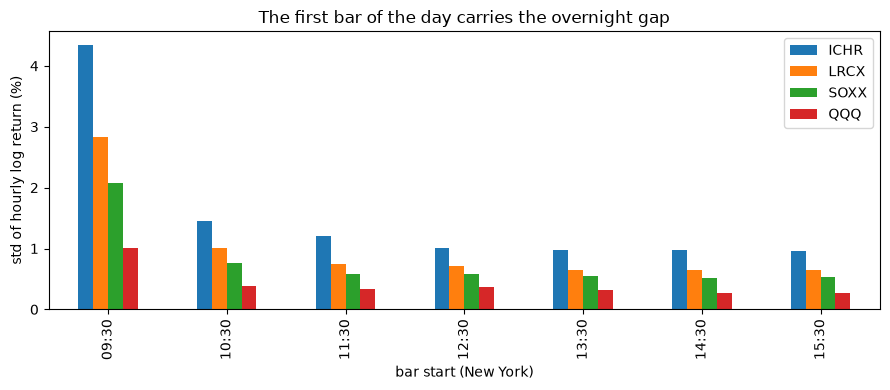

In [8]:
ax = ret_std[[TARGET, "LRCX", "SOXX", "QQQ"]].plot.bar(figsize=(9, 4))
ax.set_ylabel("std of hourly log return (%)")
ax.set_xlabel("bar start (New York)")
ax.set_title("The first bar of the day carries the overnight gap")
plt.tight_layout()

## 4. Liquidity
Dollar volume per hour = price × shares. Low dollar volume means wide spreads and noisy prices.

In [9]:
dollar_vol = pd.DataFrame(
    {t: df["close"] * df["volume"] for t, df in bars.items()}
)
(dollar_vol.median() / 1e6).sort_values().round(2).rename("median $M per hour")

ICHR       1.33
UCTT       1.68
KLAC       8.54
SOXX      44.88
LRCX      92.99
AMAT     134.16
ASML     144.96
TSM      322.91
QQQ     2480.30
NVDA    2615.38
Name: median $M per hour, dtype: float64

## 5. Big picture: normalised prices

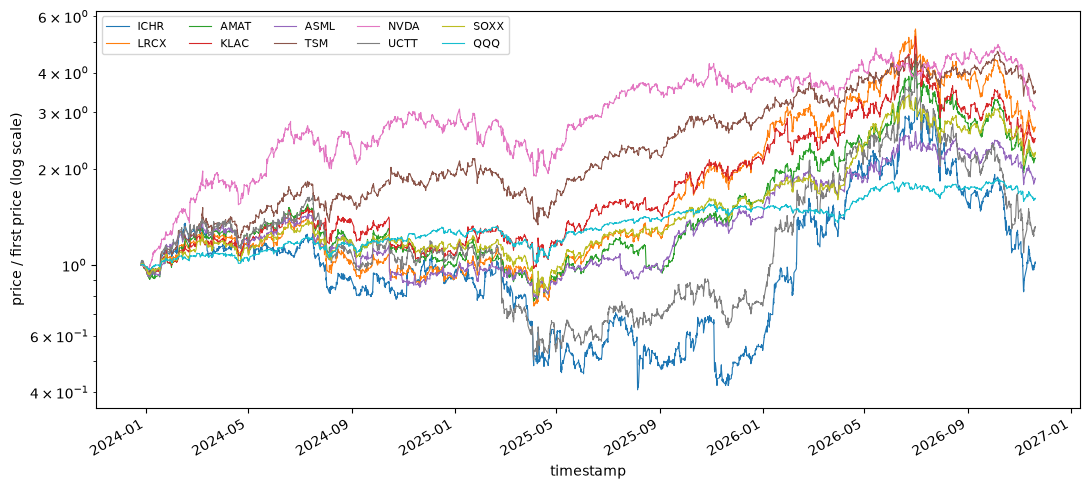

In [10]:
ax = (close / close.iloc[0]).plot(figsize=(11, 5), logy=True, lw=0.8)
ax.set_ylabel("price / first price (log scale)")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()

## 6. Contemporaneous correlation (same hour)
Not the lead-lag signal yet (that's step 2), but it shows which tickers move together at all.

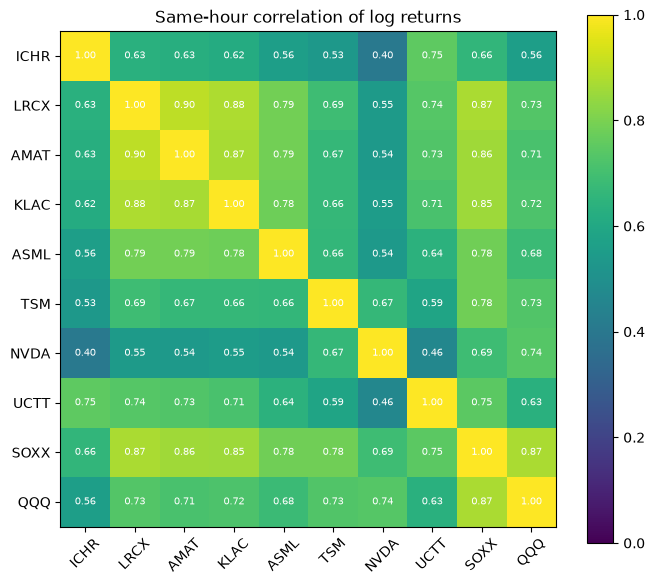

In [11]:
corr = log_ret.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im)
ax.set_title("Same-hour correlation of log returns")
plt.tight_layout()

## Notes / findings

- why do we take the log in log_ret = np.log(close).diff()
    - spread is highest for the first bar of the day
 - ICHR is the smallest in M dollar per hour, NVDA the biggest
- same-hour correlation of log returns is low for ICHR with other stocks, max 0.75 with UCTT
- there is one that is even less correlated with others and that is NVDA


## Answers to the notes

**Why `np.log(close).diff()`?** `log(P_t) − log(P_{t−1}) = log(P_t / P_{t−1})` is the *log return*:
1. **Additive over time**: the 7-hour return is the sum of the hourly log returns (% changes have to be compounded).
2. **Symmetric**: +10% then −10% leaves you at 0.99; equal up and down log moves cancel exactly.
3. **Tames extremes**: ICHR's biggest hourly moves are +33.6% / −31.1% simple, +0.29 / −0.37 log, a bit closer to normal.

For small moves they're nearly identical (1% ≈ 0.00995), so log returns still read as "about a percentage".

**Remarks on the notes**
- First-bar spread = the overnight gap; step 2 treats the 09:30 bar separately.
- ICHR ≈ $1.3M/hour vs NVDA ≈ $2.6B/hour: ~2,000× less attention, which is the premise of the project.
- ICHR's correlations (0.53–0.75) are actually fairly high for hourly returns. The ranking follows the supply chain:
  UCTT 0.75 > SOXX 0.66 > LRCX/AMAT 0.63 > NVDA 0.40.
- NVDA is weakly tied to the equipment names (~0.55) and ICHR (0.40), but strongly to TSM (0.67), SOXX (0.69) and
  QQQ (0.74): it belongs to the "AI demand / big tech" group, not the toolmakers.
- All of this is **same-hour** correlation: ICHR moves *with* the others. Whether it moves *after* them is step 2.
